# Task 1 – Requirement 3: N-Queens bằng Min-Conflicts
So sánh Min-Conflicts tiêu chuẩn và biến thể ưu tiên hậu có nhiều xung đột nhất. Hai phương pháp dùng cùng N, seed, số lần chạy và giới hạn bước. Thời gian đo gồm khởi tạo và tìm kiếm. Trung bình số bước chính tính trên mọi lần chạy; thất bại được tính đủ `MAX_STEPS`.

Biến thể cải tiến chỉ đổi cách chọn hàng: chọn ngẫu nhiên trong nhóm có số xung đột cao nhất. Cả hai chọn ngẫu nhiên cột có điểm conflict thấp nhất nếu hòa.

Thời gian dùng perf_counter quanh lời gọi giải, gồm khởi tạo bàn, tìm kiếm và tạo kết quả. Peak là số byte Python do tracemalloc theo dõi trong lượt giải riêng cùng seed, gồm ma trận đầu ra, không gồm constructor hay kiểm tra nghiệm.


In [1]:
from pathlib import Path
import sys, csv, statistics, tracemalloc
from time import perf_counter
import matplotlib.pyplot as plt
PROJECT_DIR=Path.cwd(); TASK_DIR=PROJECT_DIR if PROJECT_DIR.name=="task1" else PROJECT_DIR/"task1"
if str(TASK_DIR) not in sys.path: sys.path.insert(0,str(TASK_DIR))
from nqueens_min_conflicts import NQueensMinConflicts
N_VALUES=[4,8,10,20,50]; TRIALS=20; MAX_STEPS=2000; BASE_SEED=2026
METHODS={"Standard":"solve_standard","Improved":"solve_heuristic"}; results=[]
for n in N_VALUES:
    for trial in range(TRIALS):
        seed=BASE_SEED+trial
        for method_name,method in METHODS.items():
            solver=NQueensMinConflicts(n,max_steps=MAX_STEPS,seed=seed)
            start = perf_counter()
            result = getattr(solver, method)()
            elapsed = perf_counter() - start

            # Đo bộ nhớ ở lượt riêng để tracemalloc không làm sai lệch thời gian.
            memory_solver = NQueensMinConflicts(n, max_steps=MAX_STEPS, seed=seed)
            tracemalloc.start()
            try:
                measured = getattr(memory_solver, method)()
                _, peak_bytes = tracemalloc.get_traced_memory()
            finally:
                tracemalloc.stop()
            for key in ("success", "steps", "state"):
                assert result[key] == measured[key]
            result["solver_time"] = elapsed
            result["peak_bytes"] = peak_bytes
            if result["success"]:
                assert solver.is_solution(result["state"])
                assert result["board"]==solver.to_board(result["state"])
            results.append({"n":n,"trial":trial+1,"seed":seed,**result,"method":method_name})

print(f"Completed {len(results)} paired measurements")


Completed 200 paired measurements


In [2]:
# Thất bại được tính MAX_STEPS trong trung bình số bước chính.
summary=[]
for n in N_VALUES:
    for method_name in METHODS:
        runs=[r for r in results if r["n"]==n and r["method"]==method_name]
        successful=[r for r in runs if r["success"]]; times=[r["solver_time"] for r in runs]
        summary.append({"N":n,"Method":method_name,"Success rate":len(successful)/len(runs),
            "Avg time (s)":statistics.mean(times),"Best time (s)":min(times),"Worst time (s)":max(times),
            "Avg peak memory (KiB)":statistics.mean(r["peak_bytes"] for r in runs)/1024,
            "Avg steps (all)":statistics.mean(r["steps"] for r in runs),
            "Avg steps (success)":statistics.mean(r["steps"] for r in successful) if successful else None})
output_dir=TASK_DIR/"results"; output_dir.mkdir(exist_ok=True)
raw_fields=["n","trial","method","seed","success","steps","solver_time","peak_bytes","state"]
with (output_dir/"min_conflicts_runs.csv").open("w",newline="",encoding="utf-8-sig") as f:
    writer=csv.DictWriter(f,fieldnames=raw_fields); writer.writeheader()
    for run in results:
        writer.writerow({key:run.get(key) for key in raw_fields})
with (output_dir/"min_conflicts_results.csv").open("w",newline="",encoding="utf-8-sig") as f:
    writer=csv.DictWriter(f,fieldnames=list(summary[0].keys())); writer.writeheader(); writer.writerows(summary)
header=f"{'N':>3} {'Method':>10} {'Success':>9} {'Avg time':>12} {'Best':>10} {'Worst':>10} {'Avg steps':>11} {'Steps/success':>14}"
print(header); print("-"*len(header))
for r in summary:
    ss="N/A" if r["Avg steps (success)"] is None else f"{r['Avg steps (success)']:.1f}"
    print(f"{r['N']:>3} {r['Method']:>10} {r['Success rate']:>8.1%} {r['Avg time (s)']:>12.6f} {r['Best time (s)']:>10.6f} {r['Worst time (s)']:>10.6f} {r['Avg steps (all)']:>11.1f} {ss:>14}")

print("Mean peak memory (KiB):")
for row in summary:
    print(row["N"], row["Method"], round(row["Avg peak memory (KiB)"], 2))


  N     Method   Success     Avg time       Best      Worst   Avg steps  Steps/success
--------------------------------------------------------------------------------------
  4   Standard   100.0%     0.000164   0.000037   0.000464        12.7           12.7
  4   Improved   100.0%     0.000165   0.000030   0.000681        12.1           12.1
  8   Standard   100.0%     0.001189   0.000199   0.006248        39.4           39.4
  8   Improved    85.0%     0.010406   0.000135   0.069939       345.1           53.0
 10   Standard   100.0%     0.003203   0.000874   0.009472        74.5           74.5
 10   Improved   100.0%     0.005014   0.000349   0.019354       117.7          117.7
 20   Standard   100.0%     0.010303   0.004306   0.031455        72.0           72.0
 20   Improved   100.0%     0.007094   0.002759   0.017239        46.0           46.0
 50   Standard   100.0%     0.078080   0.034153   0.140769        95.2           95.2
 50   Improved   100.0%     0.069221   0.035298   0.

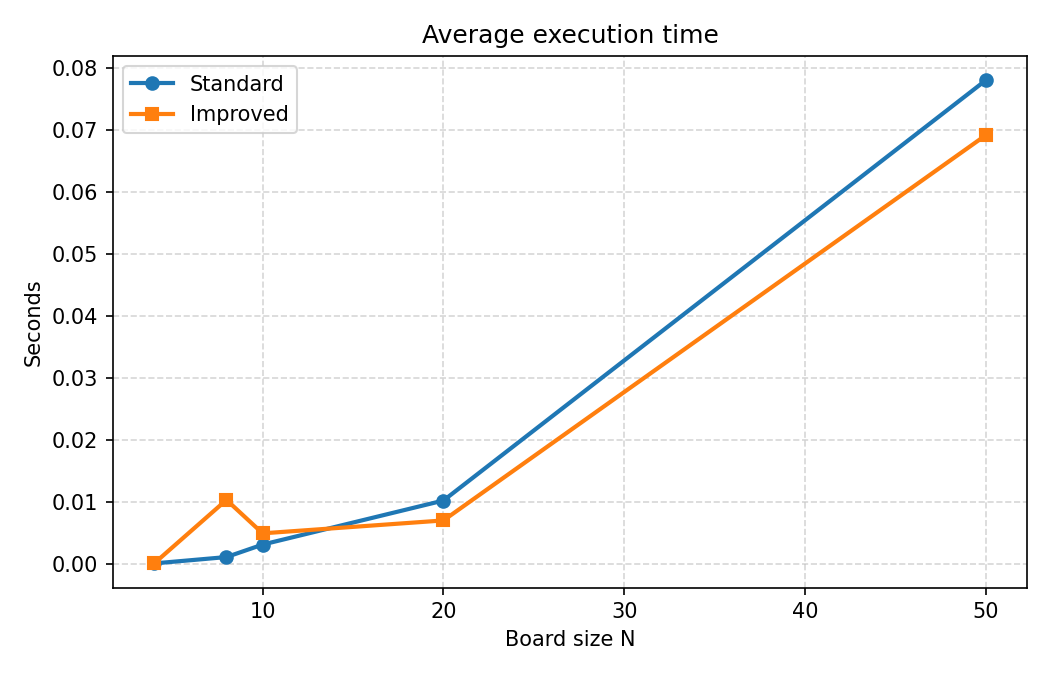

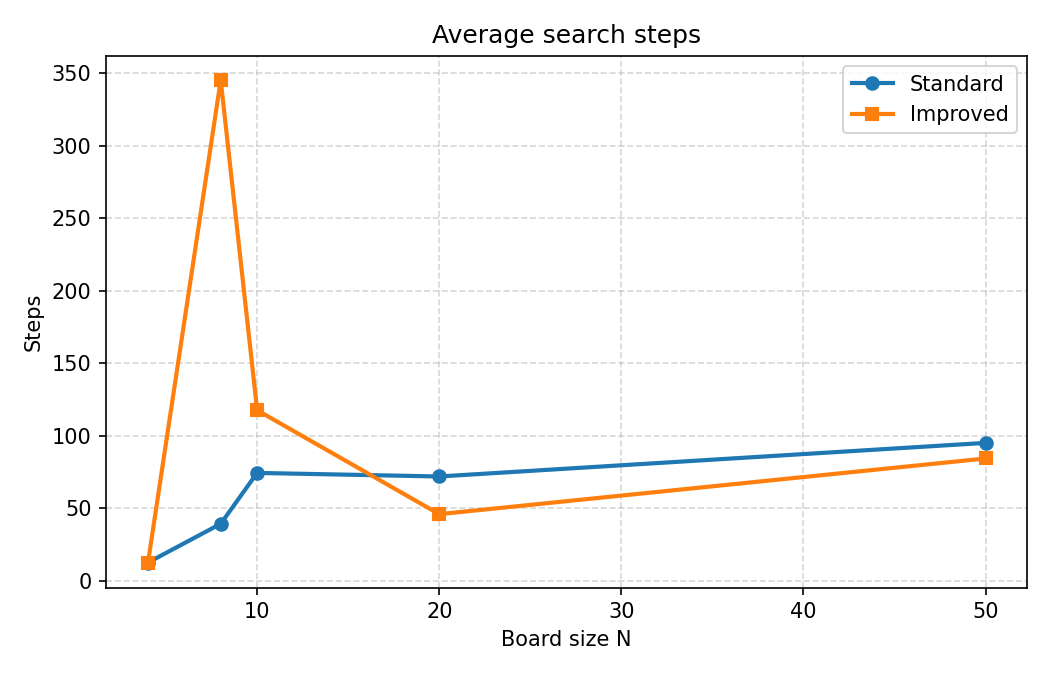

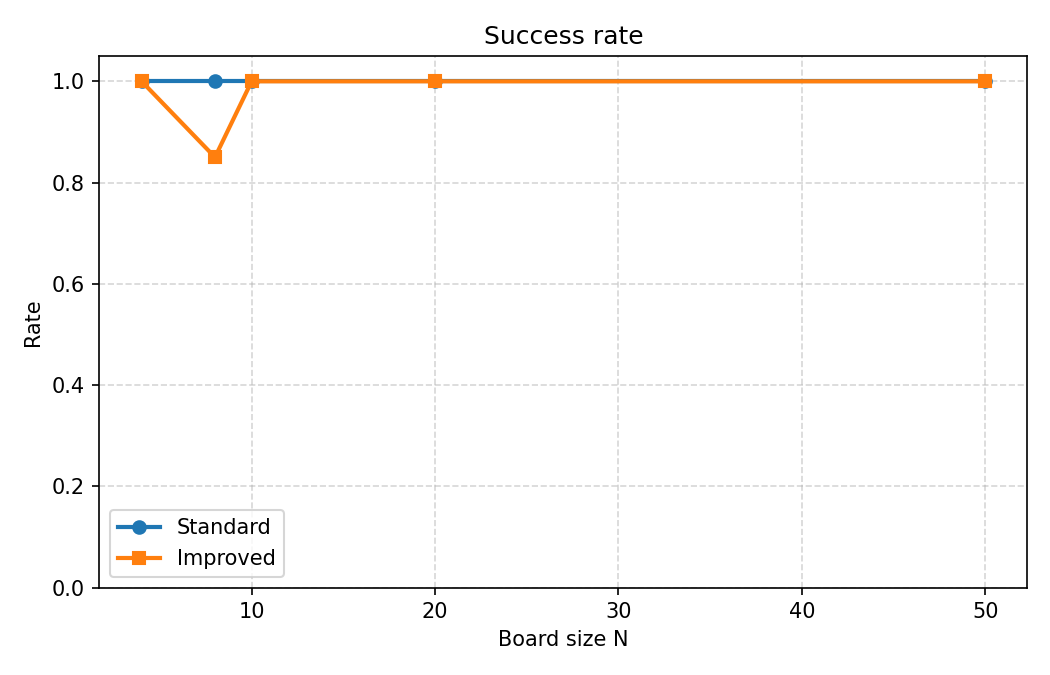

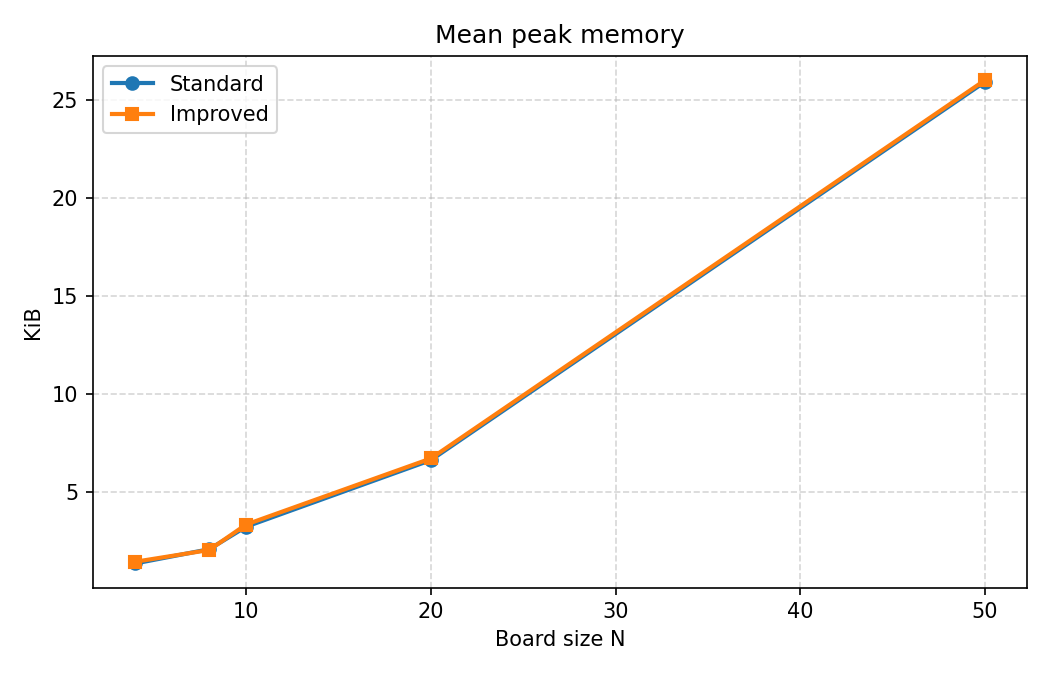

In [3]:
for metric,title,ylabel,filename in [("Avg time (s)","Average execution time","Seconds","min_conflicts_time.png"),("Avg steps (all)","Average search steps","Steps","min_conflicts_steps.png"),("Success rate","Success rate","Rate","min_conflicts_success_rate.png"),("Avg peak memory (KiB)","Mean peak memory","KiB","min_conflicts_peak_memory.png")]:
    fig,ax=plt.subplots(figsize=(7,4.5))
    for name,marker in [("Standard","o"),("Improved","s")]:
        rows=[r for r in summary if r["Method"]==name]
        ax.plot([r["N"] for r in rows],[r[metric] for r in rows],marker=marker,linewidth=2,label=name)
    ax.set_title(title); ax.set_xlabel("Board size N"); ax.set_ylabel(ylabel)
    if metric=="Success rate": ax.set_ylim(0,1.05)
    ax.grid(True,linestyle="--",alpha=.5); ax.legend(); fig.tight_layout()
    fig.savefig(output_dir/filename,dpi=150)
    plt.show()
    plt.close(fig)
